In [ ]:
# IMPORTS
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# IMPORT OWN FILES
sys.path.append(os.path.abspath(".."))

In [ ]:
import importlib.util
from pathlib import Path

# Determine parent folder
base_dir = Path.cwd().parent
path = base_dir / "pipeline_paths_mnt.py"

# Import module dynamically
spec = importlib.util.spec_from_file_location("ppaths", path)
ppaths = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ppaths)

# to keep consistent paths
run_vars = "mg_200_mc_200_mhvg1000"
pp = ppaths.PipelinePaths("dev", full_pipeline_run_vars=run_vars)

base path found (/mnt/12tb_dsk3/workspaces): True
data path found (/mnt/12tb_dsk3/workspaces/isabell): True


In [ ]:
def load_scores(path):
    df = pd.read_csv(path)
    return df["y_true"].to_numpy(dtype=np.int_), df["y_prob"].to_numpy(dtype=np.float64)

def draw_roc(axes, panels, run_vars):
    for ax, (title, runs) in zip(axes, panels.items()):
        for i, (cell_type, date) in enumerate(runs.items()):
            path = pp.binn_test_results_path / f"{date}_binn_test_results_{cell_type}_{run_vars}.csv"
            y_true, y_prob = load_scores(path)
            RocCurveDisplay.from_predictions(
                y_true, y_prob,
                ax=ax,
                name=cell_type,
                plot_chance_level=(i == len(runs) - 1),
            )
            disp.line_.set_color(f"C{i}")
        ax.set_title(title)
        ax.set_aspect("equal")
        ax.legend(loc="lower right", fontsize=9)

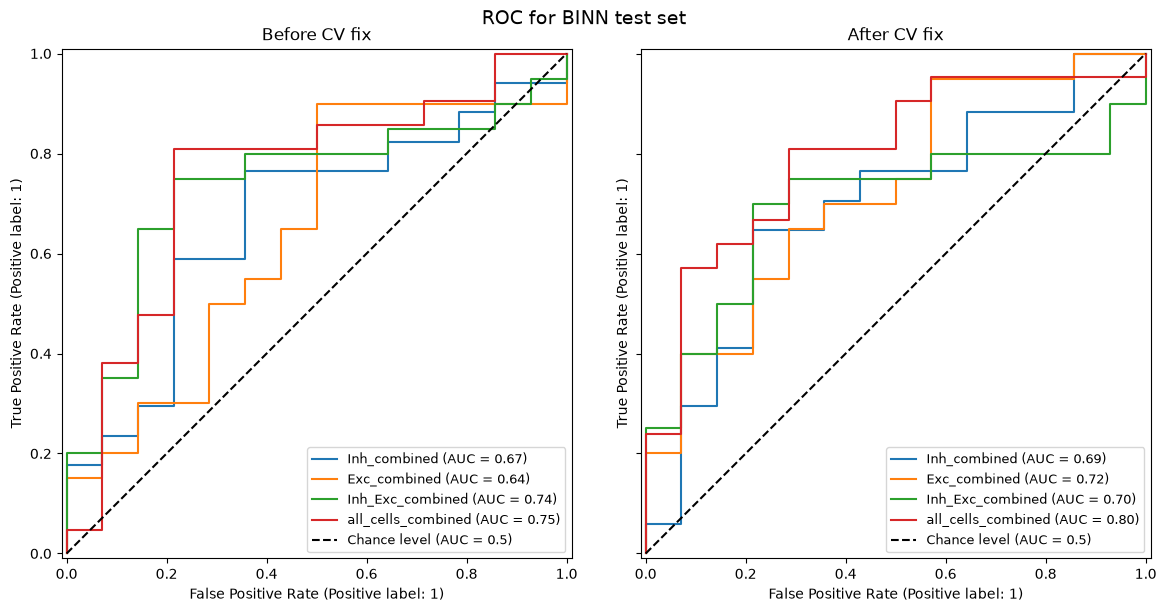

In [ ]:
panels = {
    "Before CV fix": {
        "Inh_combined": "261110_1119",
        "Exc_combined": "261110_1119",
        "Inh_Exc_combined": "261110_1119",
        "all_cells_combined": "261110_1119",
    },
    "After CV fix": {
        "Inh_combined": "261110_0958",
        "Exc_combined": "261110_1005",
        "Inh_Exc_combined": "261110_1005",
        "all_cells_combined": "261110_1005",
    },
}

fig, axes = plt.subplots(1, len(panels), figsize=(12, 6), sharex=True, sharey=True)

draw_roc(axes, panels, run_vars)

fig.suptitle("ROC for BINN test set", fontsize=14)
plt.tight_layout()
plt.savefig(pp.binn_test_results_path / f'{your_title}.png', dpi=300)
plt.show()